# Dữ liệu mua sắm siêu thị (Online Retail)
**Nguồn trong đề:** Lab 1 — bài tập EDA siêu thị (1.2.3)

Notebook độc lập cho một tập dữ liệu; code lấy từ các ô tương ứng của notebook Lab1 (giữ nguyên, ô nào chỉnh có ghi `# [Chỉnh]`).

In [1]:
# Thư viện dùng chung (đề import rải rác ở nhiều ô; gom lại để notebook chạy độc lập)
import os
if os.path.basename(os.getcwd()) == 'notebooks':   # chạy notebook từ thư mục notebooks/ thì lùi ra thư mục gốc chứa data/
    os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set()
retail = pd.read_excel("data/Online_Retail.xlsx")
print(retail.shape)
retail.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
retail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
print(retail.isnull().sum())
print("Số dòng trùng lặp:", retail.duplicated().sum())
retail.describe()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Số dòng trùng lặp: 5268


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


Dữ liệu có đơn hàng bị hủy (InvoiceNo bắt đầu bằng chữ C, Quantity âm) và giá/số lượng không hợp lệ; lọc các dòng này trước khi tính doanh thu.

In [5]:
print("Đơn bị hủy:", retail['InvoiceNo'].astype(str).str.startswith('C').sum())
print("Quantity <= 0:", (retail['Quantity'] <= 0).sum(), "| UnitPrice <= 0:", (retail['UnitPrice'] <= 0).sum())
clean = retail[(retail['Quantity'] > 0) & (retail['UnitPrice'] > 0)].drop_duplicates().copy()
clean['Revenue'] = clean['Quantity'] * clean['UnitPrice']
clean['Month'] = clean['InvoiceDate'].dt.to_period('M').astype(str)
print(clean.shape)

Đơn bị hủy: 9288
Quantity <= 0: 10624 | UnitPrice <= 0: 2517


(524878, 10)


Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


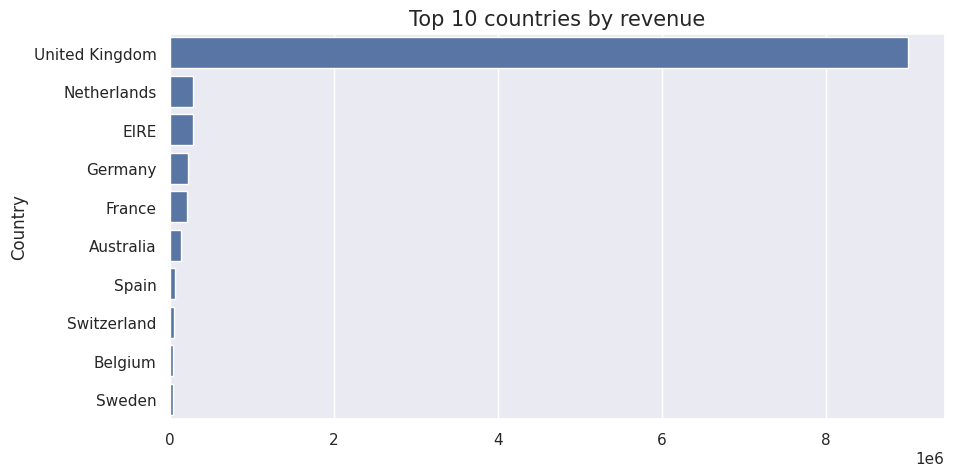

In [6]:
# 10 quốc gia có doanh thu cao nhất
top_country = clean.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)
print(top_country)
plt.figure(figsize=(10,5))
ax = sns.barplot(x=top_country.values, y=top_country.index)
ax.set_title('Top 10 countries by revenue', fontsize=15)
plt.show()

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


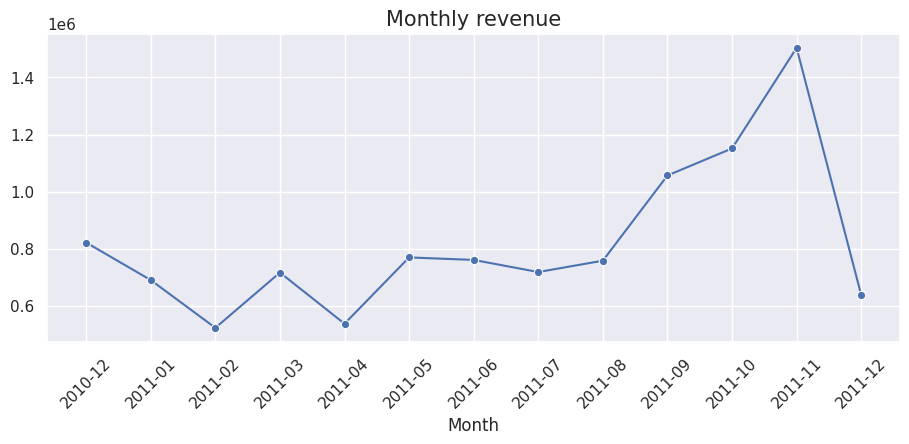

In [7]:
# 10 sản phẩm bán nhiều nhất và doanh thu theo tháng
top_prod = clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
print(top_prod)
monthly = clean.groupby('Month')['Revenue'].sum()
plt.figure(figsize=(11,4))
ax = sns.lineplot(x=monthly.index, y=monthly.values, marker='o')
ax.set_title('Monthly revenue', fontsize=15)
plt.xticks(rotation=45)
plt.show()

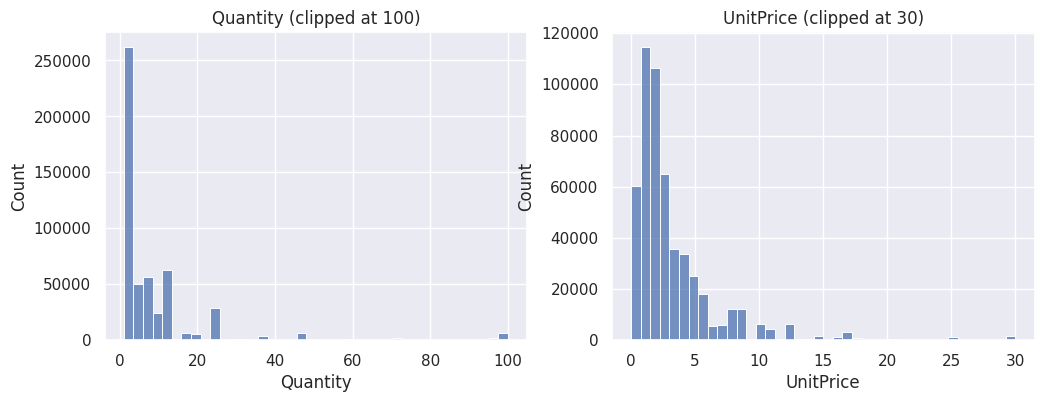

In [8]:
# Phân bố số lượng và đơn giá (thang log do lệch phải mạnh)
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(clean['Quantity'].clip(upper=100), bins=40, ax=axes[0]).set_title('Quantity (clipped at 100)')
sns.histplot(clean['UnitPrice'].clip(upper=30), bins=40, ax=axes[1]).set_title('UnitPrice (clipped at 30)')
plt.show()